# 04. Chronos-2 validation

This notebook answers how the chosen model compares with the benchmark and how good its
interval is. It uses 30 windows without overlap, 60 days in all, or 4.3% of the series. Windows are
what count here: Chronos is not trained on this data, so there is no train/validation split.

It writes `backtest_30_windows.csv`, which the final notebook reads for the interval cap. If that file
exists, it is reused, so delete it to compute everything again.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160, "display.max_columns", 40)
data, weather_fc = load_data()
y = data["y"].to_numpy(float)
FEATURES = [c for c in weather_fc.columns if c != "ds"]
print(len(data), "hours, last one:", data["ds"].iloc[-1])

from pathlib import Path
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

FILE, LONG, MAIN = "backtest_30_windows.csv", 30, "Chronos+weather"

33480 hours, last one: 2026-10-27 00:00:00


In [2]:
if Path(FILE).exists():
    bt = pd.read_csv(FILE)
    print("reused", FILE)
else:
    pipe = load_chronos()
    frames = []
    for k, past_df, test_df in origins(data, LONG):
        b = snaive(past_df["y"].to_numpy(float))
        frame = pd.DataFrame({"window": k, "step": np.arange(1, H + 1), "ds": test_df["ds"].to_numpy(),
                              "daylight": test_df["daylight"].to_numpy(), "actual": test_df["y"].to_numpy(float),
                              "benchmark": b[0], "benchmark lo": b[1], "benchmark hi": b[2]})
        for name, feats in {"Chronos": [], MAIN: FEATURES}.items():
            out = chronos_predict(pipe, past_df, test_df, feats)
            frame[name], frame[f"{name} lo"], frame[f"{name} hi"] = out["point"], out["lo"], out["hi"]
        frames.append(frame)
        print("window", k, "done")
    bt = pd.concat(frames, ignore_index=True)
    bt.to_csv(FILE, index=False)
print(bt["window"].nunique(), "windows,", bt["ds"].min(), "to", bt["ds"].max())

reused backtest_30_windows.csv
30 windows, 2026-08-28 01:00:00 to 2026-10-27 00:00:00


## Against the benchmark

The bounds of "Chronos" in this table are its own. The weather runs use the actual weather of each window, so
"Chronos" and "Chronos+weather" bracket what to expect from a real weather forecast.

In [3]:
COLUMNS = ["Chronos", MAIN, "benchmark"]
rows = {}
for part, first in {"all 48 hours": 1, "day 2": 25}.items():
    for metric in ("RMSE", "MAPE", "Winkler"):
        table = window_table(bt, COLUMNS, metric, first=first)
        for c in COLUMNS:
            rows.setdefault((part, c), {})[metric] = round(table.loc[c, "mean"], 1)
            rows[(part, c)][f"{metric} wins /30"] = int(table.loc[c, "beats benchmark"])
pd.DataFrame(rows).T

RMSE  RMSE wins /30   MAPE  MAPE wins /30  Winkler  Winkler wins /30
all 48 hours Chronos          259.6           22.0  142.4           16.0   1104.6              20.0
             Chronos+weather  189.0           28.0   73.8           23.0    887.4              26.0
             benchmark        297.1            0.0  193.4            0.0   2201.8               0.0
day 2        Chronos          288.2           18.0  135.7           16.0   1268.8              13.0
             Chronos+weather  195.5           26.0   70.9           21.0    978.4              22.0
             benchmark        310.0            0.0  154.9            0.0   2061.3               0.0

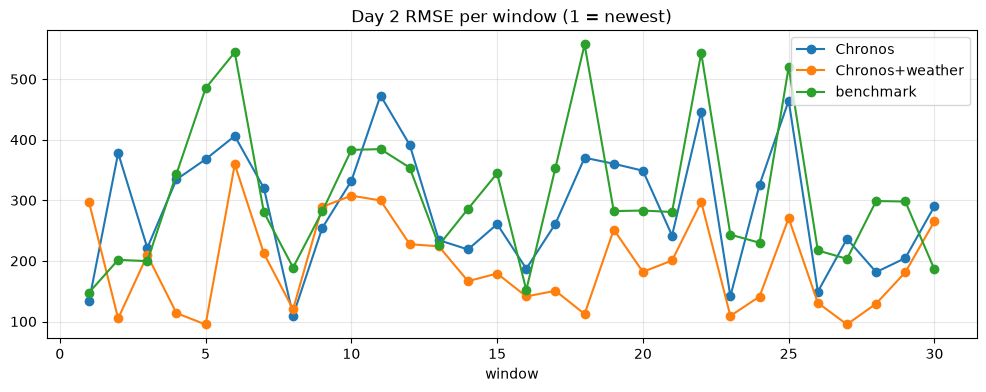

In [4]:
table = window_table(bt, COLUMNS, "RMSE", first=25)
plot = table.drop(columns=["mean", "beats benchmark"]).T
plot.index = [int(c[1:]) for c in plot.index]
plot.plot(marker="o", figsize=(12, 4), title="Day 2 RMSE per window (1 = newest)")
plt.xlabel("window"); plt.show()

## Blending with the benchmark

Only the point forecast is blended. The bounds stay those of Chronos, because Winkler depends on the bounds
alone, so a blend cannot change it unless the blend leaves the interval.

In [5]:
day2 = bt[bt["step"] > 24]
rows = {}
for w in (1.0, 0.75, 0.5):
    records, wins = [], {"RMSE": 0, "MAPE": 0}
    for k, g in day2.groupby("window"):
        point = w * g[MAIN] + (1 - w) * g["benchmark"]
        ours = {"RMSE": rmse(g["actual"], point), "MAPE": mape(g["actual"], point)}
        base = {"RMSE": rmse(g["actual"], g["benchmark"]), "MAPE": mape(g["actual"], g["benchmark"])}
        records.append(ours)
        for m in wins:
            wins[m] += int(ours[m] < base[m])
    rows[f"Chronos weight {w}"] = {**pd.DataFrame(records).mean().round(1).to_dict(), "wins RMSE": wins["RMSE"], "wins MAPE": wins["MAPE"]}
pd.DataFrame(rows).T

,RMSE,MAPE,wins RMSE,wins MAPE
Chronos weight 1.0,195.5,70.9,26.0,21.0
Chronos weight 0.75,202.2,87.5,27.0,21.0
Chronos weight 0.5,227.6,107.5,28.0,24.0


## The interval

Three checks. First the raw interval scaled up and down, then the conformal recipe from the labs with its radius
taken from the other windows, then a cap on the half-width. The cap uses older windows only, so that it could
have been applied at the time.

In [6]:
def wide(df, s):
    point, lo, hi = df[MAIN].to_numpy(), df[f"{MAIN} lo"].to_numpy(), df[f"{MAIN} hi"].to_numpy()
    return np.clip(point - s * (point - lo), 0, None), point + s * (hi - point)

rows = {}
for s in (1.2, 1.0, 0.9, 0.8, 0.7, 0.6):
    lo, hi = wide(day2, s)
    rows[f"scale {s}"] = score(day2["actual"], day2[MAIN], lo, hi) | {"width": float(np.mean(hi - lo))}

records = []
for k, g in day2.groupby("window"):
    others = day2[day2["window"] != k]
    radius = float(np.quantile(np.abs(others["actual"] - others[MAIN]), 0.95))
    lo, hi = np.clip(g[MAIN] - radius, 0, None), g[MAIN] + radius
    records.append(score(g["actual"], g[MAIN], lo, hi) | {"width": float(np.mean(hi - lo))})
rows["conformal, other windows"] = pd.DataFrame(records).mean().to_dict()
pd.DataFrame(rows).T[["Winkler", "coverage", "width"]].round(2)

,Winkler,coverage,width
scale 1.2,1105.70,1.00,1099.32
scale 1.0,978.42,0.98,935.41
scale 0.9,928.13,0.96,841.86
scale 0.8,924.18,0.92,748.32
scale 0.7,984.80,0.87,654.78
scale 0.6,1139.12,0.80,561.24
"conformal, other windows",1012.81,0.95,759.93


In [7]:
bt["up"] = bt[f"{MAIN} hi"] - bt[MAIN]
bt["dn"] = bt[MAIN] - bt[f"{MAIN} lo"]
day2 = bt[bt["step"] > 24]

rows = {}
for c in (np.inf, 1.5, 1.2, 1.0, 0.9, 0.8, 0.7, 0.6, 0.5):
    records = []
    for k in range(1, 21):                   # the 10 oldest windows only supply the cap
        g = day2[day2["window"] == k].sort_values("step")
        older = day2[day2["window"] > k]
        up = older.groupby("step")["up"].median().reindex(g["step"]).to_numpy() * c
        dn = older.groupby("step")["dn"].median().reindex(g["step"]).to_numpy() * c
        point = g[MAIN].to_numpy()
        hi, lo = point + np.minimum(g["up"].to_numpy(), up), np.clip(point - np.minimum(g["dn"].to_numpy(), dn), 0, None)
        records.append(score(g["actual"], point, lo, hi) | {"width": float(np.mean(hi - lo))})
    means = pd.DataFrame(records)
    rows["no cap" if np.isinf(c) else f"cap C = {c}"] = {**means.mean().to_dict(), "median Winkler": means["Winkler"].median()}
pd.DataFrame(rows).T[["Winkler", "median Winkler", "coverage", "width"]].round(2)

,Winkler,median Winkler,coverage,width
no cap,1031.28,1049.30,0.98,985.26
cap C = 1.5,1013.17,1019.04,0.98,967.16
cap C = 1.2,979.95,944.71,0.97,907.85
cap C = 1.0,965.14,843.35,0.97,814.57
cap C = 0.9,965.42,773.73,0.95,745.53
cap C = 0.8,1006.77,695.74,0.92,670.22
cap C = 0.7,1112.40,645.22,0.88,592.00
cap C = 0.6,1299.22,735.84,0.82,511.50
cap C = 0.5,1609.16,1090.82,0.74,429.25


## The width of the real forecast

Chronos gets the weather forecast here, which it never saw in the windows above. If the real interval is much wider
than in any window, the windows say little about it.

In [8]:
pipe = load_chronos() if "pipe" not in globals() else pipe
real = chronos_predict(pipe, data, weather_fc, FEATURES)
width = pd.Series(real["hi"] - real["lo"])
by_window = (day2[f"{MAIN} hi"] - day2[f"{MAIN} lo"]).groupby(day2["window"]).mean()
corr = pd.DataFrame({"width": by_window, "rmse": day2.groupby("window").apply(lambda g: rmse(g["actual"], g[MAIN]), include_groups=False)}).corr().iloc[0, 1]
print(f"real day 2 width {width[24:].mean():.0f}; windows: median {by_window.median():.0f}, max {by_window.max():.0f}")
print(f"correlation of window width with window RMSE: {corr:.2f}")
error = (day2["actual"] - day2[MAIN]).abs()
print(f"day 2 absolute error: 95th percentile {error.quantile(0.95):.0f}, daylight {error[day2['daylight'] == 1].quantile(0.95):.0f}, night {error[day2['daylight'] == 0].quantile(0.95):.0f}")

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:   5%|▌         | 9/170 [00:00<00:01, 89.48it/s]

Loading weights:  11%|█         | 18/170 [00:00<00:03, 39.08it/s]

Loading weights:  14%|█▍        | 24/170 [00:00<00:03, 37.50it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 282.62it/s]

real day 2 width 1480; windows: median 940, max 1139
correlation of window width with window RMSE: 0.29
day 2 absolute error: 95th percentile 419, daylight 477, night 307


## Residuals

A good forecast leaves errors with no pattern, so we look for bias by hour and for autocorrelation.

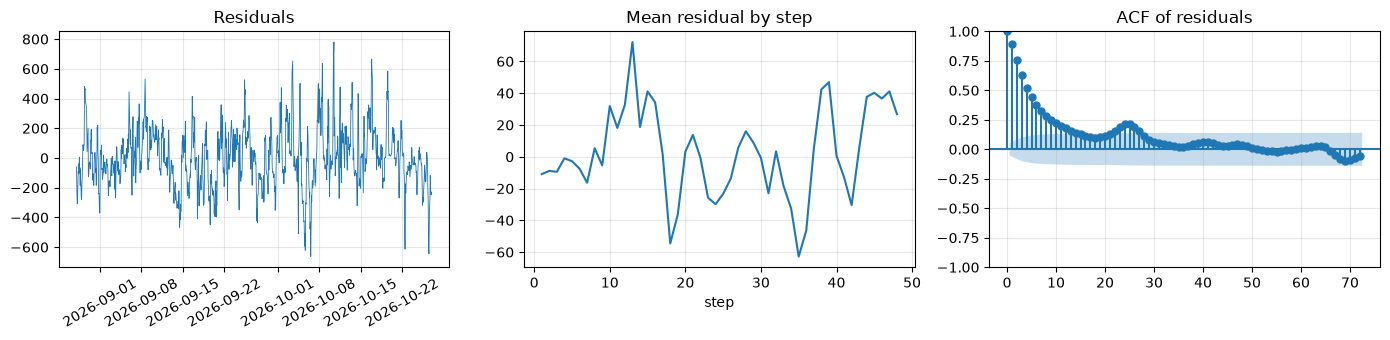

mean residual 2.4, by day: [2.6, 2.2]
      lb_stat  lb_pvalue
24  4312.4484        0.0
48  4552.6647        0.0


In [9]:
bt = bt.sort_values(["window", "step"], ascending=[False, True])
bt["residual"] = bt["actual"] - bt[MAIN]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(pd.to_datetime(bt["ds"]), bt["residual"], lw=0.6); ax[0].set_title("Residuals"); ax[0].tick_params(axis="x", rotation=30)
bt.groupby("step")["residual"].mean().plot(ax=ax[1], title="Mean residual by step")
plot_acf(bt["residual"], lags=72, ax=ax[2], title="ACF of residuals")
plt.tight_layout(); plt.show()
print(f"mean residual {bt['residual'].mean():.1f}, by day: {bt.groupby(bt['step'] > 24)['residual'].mean().round(1).tolist()}")
print(acorr_ljungbox(bt["residual"], lags=[24, 48]).round(4).to_string())

## What this means

- **Against the benchmark.** On day 2, Chronos+weather beats it in 26 of 30 windows on RMSE (196 against 310), 21 on
  MAPE (71 against 155) and 22 on Winkler (978 against 2061). It is not a guarantee: the benchmark still wins some
  windows, and all of these windows use actual weather.
- **How much the weather contributes.** Without it, day 2 RMSE is 288. A real weather forecast is likely to land
  between the two, but one day can fall outside that range.
- **Blending.** A 75/25 blend adds one RMSE win and worsens both means (RMSE 202, MAPE 88). A 50/50 blend wins more often
  (28 RMSE, 24 MAPE) but is clearly worse on the means (RMSE 228, MAPE 108). Which matters depends on how "beating the
  benchmark" is judged.
- **The raw interval is too wide.** Coverage on day 2 is 0.98. Scaling it to 0.8-0.9 lowers Winkler to about 925, with
  coverage 0.92-0.96. The conformal recipe gives 1013, so the shape from Chronos is better than a flat radius.
- **The real interval is unusual.** Its day 2 width is 1480, above the 1139 of the widest window, and in the windows
  width only loosely tracks error (correlation 0.29).
- **The cap.** On the 20 windows that have older windows behind them, Winkler is 1031 with no cap, 980 at C = 1.2,
  965 at 1.0 and 965 at 0.9, then rises fast: 1007 at 0.8 and 1609 at 0.5. `CAP = 1.0` gives the lowest mean with
  coverage 0.97. 0.9 ties on the mean, but its coverage is 0.95 with actual weather, and forecast weather adds
  error. Much narrower is not an option: the 95th percentile of the absolute error on day 2 is 419, which needs a
  width near 840. The check was prompted by the public Winkler of 956, equal to the file's width, but the value comes
  from these windows. It was never tested with forecast weather, so a large weather error would cost more than before.
- **Residuals.** They are not white noise: autocorrelation is 0.89 at lag 1 and Ljung-Box rejects clearly, which means
  an error tends to last for hours. It falls to 0.22 at lag 24 and 0.04 at lag 48. The mean residual is 2.4, so
  there is no meaningful bias overall.